# Deep Convolutional GAN

In [6]:
import torch
import torch.nn as nn

torch.manual_seed(1)
dc_codings_dim = 100

dc_generator = nn.Sequential(
    nn.Linear(dc_codings_dim, 128 * 8 * 8),
    nn.Unflatten(dim=1, unflattened_size=(128, 8, 8)),
    nn.BatchNorm2d(128),
    nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 64 x 16 x 16
    nn.BatchNorm2d(64),
    nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1), nn.ReLU(),   # 32 x 32 x 32
    nn.BatchNorm2d(32),
    nn.ConvTranspose2d(32, 3, kernel_size=3, stride=2, padding=1, output_padding=1), nn.Tanh()     # 3 x 64 x 64
).to("cuda")

dc_discriminator = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=5, stride=2, padding=2), nn.LeakyReLU(0.2),    # 32 x 32 x 32
    nn.Dropout(0.4),
    nn.Conv2d(32, 64, kernel_size=5, stride=2, padding=2), nn.LeakyReLU(0.2),   # 64 x 16 x 16
    nn.Dropout(0.4),
    nn.Conv2d(64, 128, kernel_size=5, stride=2, padding=2), nn.LeakyReLU(0.2),  # 128 x 8 x 8
    nn.Dropout(0.4),
    nn.Flatten(),
    nn.Linear(128 * 8 * 8, 1), nn.Sigmoid()
).to("cuda")

# GAN Training function

In [7]:
import matplotlib.pyplot as plt

def plot_image(image):
    image = (image.detach().cpu() + 1) / 2          # [-1, 1] -> [0, 1]
    plt.imshow(image.permute(1, 2, 0).clamp(0, 1))
    plt.axis("off")

def plot_multiple_images(images, n_cols=None):
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols, n_rows))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plot_image(image)

def train_gan(generator, discriminator, train_loader, codings_dim, n_epochs=20,
              g_lr=2e-4, d_lr=2e-4):
    criterion = nn.BCELoss()
    generator_opt = torch.optim.NAdam(generator.parameters(), lr=g_lr, betas=(0.5, 0.999))
    discriminator_opt = torch.optim.NAdam(discriminator.parameters(), lr=d_lr, betas=(0.5, 0.999))
    for epoch in range(n_epochs):
        print(f"Epoch {epoch + 1}/{n_epochs}", end="")
        for real_images in train_loader:
            real_images = real_images.to("cuda")
            pred_real = discriminator(real_images)
            batch_size = real_images.size(0)
            ones = torch.ones(batch_size, 1, device="cuda")
            real_loss = criterion(pred_real, ones)
            codings = torch.randn(batch_size, codings_dim, device="cuda")
            fake_images = generator(codings).detach()
            pred_fake = discriminator(fake_images)
            zeros = torch.zeros(batch_size, 1, device="cuda")
            fake_loss = criterion(pred_fake, zeros)
            discriminator_loss = real_loss + fake_loss
            discriminator_opt.zero_grad()
            discriminator_loss.backward()
            discriminator_opt.step()

            codings = torch.randn(batch_size, codings_dim, device="cuda")
            fake_images = generator(codings)
            for p in discriminator.parameters():
                p.requires_grad = False
            pred_fake = discriminator(fake_images)
            generator_loss = criterion(pred_fake, ones)
            generator_opt.zero_grad()
            generator_loss.backward()
            generator_opt.step()
            for p in discriminator.parameters():
                p.requires_grad = True
        print(f" | discriminator loss: {discriminator_loss.item():.4f}", end="")
        print(f" | generator loss: {generator_loss.item():.4f}")
        if epoch % 10 == 0 or epoch == n_epochs - 1:
            plot_multiple_images(fake_images[:16].detach(), 8)
            plt.show()

# Load the dataset

In [8]:

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import random

class CelebAFolder(Dataset):
    def __init__(self, root, transform=None):
        self.root = Path(root)
        self.image_paths = sorted(
            p for p in self.root.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(
            self.image_paths[index]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image

transform = transforms.Compose([
    transforms.CenterCrop(178),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

# Load all images from your existing folder
full_dataset = CelebAFolder(
    root="./img_align_celeba/img_align_celeba",
    transform=transform
)

# Split into training and testing sets
train_size = int(0.9 * len(full_dataset))
test_size = len(full_dataset) - train_size

train_dataset, test_dataset = torch.utils.data.random_split(
    full_dataset,
    [train_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

Training images: 182339
Test images: 20260


# Do the training

Epoch 1/20 | discriminator loss: 1.2023 | generator loss: 0.9561


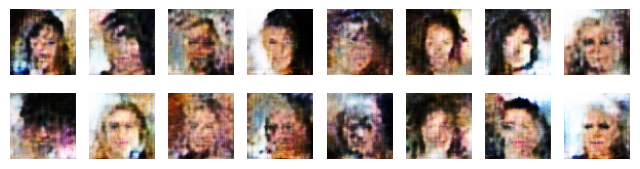

Epoch 2/20 | discriminator loss: 1.1402 | generator loss: 0.8403
Epoch 3/20 | discriminator loss: 1.1223 | generator loss: 1.2351
Epoch 4/20 | discriminator loss: 1.0849 | generator loss: 1.0457
Epoch 5/20 | discriminator loss: 0.9956 | generator loss: 0.9344
Epoch 6/20 | discriminator loss: 0.9371 | generator loss: 1.0864
Epoch 7/20 | discriminator loss: 1.0276 | generator loss: 1.3699
Epoch 8/20 | discriminator loss: 0.9480 | generator loss: 1.3103
Epoch 9/20 | discriminator loss: 0.9258 | generator loss: 1.2850
Epoch 10/20 | discriminator loss: 0.9505 | generator loss: 1.5167
Epoch 11/20 | discriminator loss: 1.0121 | generator loss: 1.2902


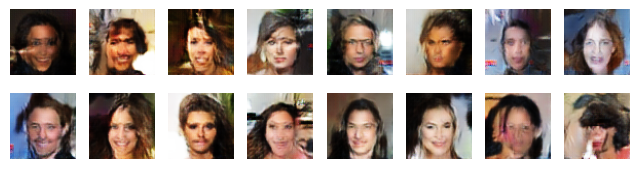

Epoch 12/20 | discriminator loss: 1.1637 | generator loss: 1.5274
Epoch 13/20 | discriminator loss: 1.1610 | generator loss: 0.7322
Epoch 14/20 | discriminator loss: 0.8719 | generator loss: 0.9951
Epoch 15/20 | discriminator loss: 0.8994 | generator loss: 1.5711
Epoch 16/20 | discriminator loss: 0.9444 | generator loss: 1.7993
Epoch 17/20 | discriminator loss: 0.9257 | generator loss: 1.3171
Epoch 18/20 | discriminator loss: 1.1315 | generator loss: 1.5749
Epoch 19/20 | discriminator loss: 0.8739 | generator loss: 1.5456
Epoch 20/20 | discriminator loss: 0.8899 | generator loss: 1.3868


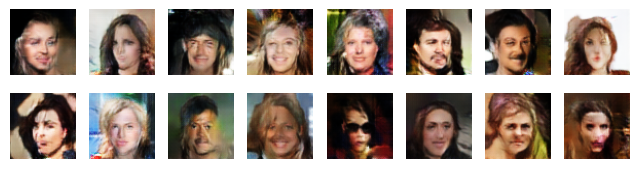

In [9]:
torch.manual_seed(42)
train_gan(dc_generator, dc_discriminator, train_loader, dc_codings_dim)

# Generate Images

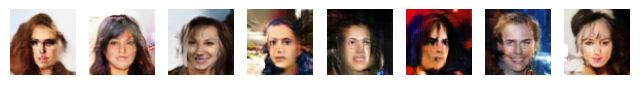

In [10]:
torch.manual_seed(42)

dc_generator.eval()
with torch.no_grad():
    codings = torch.randn(8, dc_codings_dim, device="cuda")
    generated_images = dc_generator(codings)

plot_multiple_images(generated_images, 8)